# Código comparación 2 vocales con las 2 soluciones por método

In [ ]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
%config InlineBackend.figure_format = 'svg'
from MetricasRendimiento import MetricasRendimiento
import ray
from matplotlib.backends.backend_pdf import PdfPages
import textwrap
import pandas as pd

#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5

@ray.remote
def procesar_archivo(nombre, carpeta_base,vocal, parametros):

    ruta_archivo = Path(carpeta_base) / nombre
    df = pd.read_csv(ruta_archivo, sep=',')
    
    fs_r = 8000
    tiempos = df['t_ms'].values

    # ==================================================================

    señal_MBK = df['MBK'].values
    señal_MBK = Funciones.Detrend(tiempos, señal_MBK)
    señal_MBK = señal_MBK - np.mean(señal_MBK)

    señal_ACC = -df['ACC'].values
    señal_ACC = señal_ACC - np.mean(señal_ACC)
    señal_ACC = Funciones.Detrend(tiempos, señal_ACC)
    señal_ACC = señal_ACC - np.mean(señal_ACC)

    señal_EGG = df['MBK'].values
    señal_EGG = Funciones.Detrend(tiempos, señal_EGG)
    señal_dEGG = np.gradient(señal_EGG)

    flujo_OVV = df['flujo_OVV'].values
    dflujo_OVV = np.gradient(flujo_OVV)

    # ==================================================================
    # CONMF

    resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK,acelerometro=señal_ACC,dEGG=señal_dEGG,tiempos=tiempos,fs=fs_r,**parametros["CONMF"])
    
    # ==================================================================
    # NMF SPEECH

    resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK,dEGG=señal_dEGG,tiempos=tiempos,fs=fs_r,**parametros["NMF_speech"])

    # ==================================================================
    # NMF ACC

    resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC,dEGG=señal_dEGG,tiempos=tiempos,fs=fs_r,**parametros["NMF_acc"])

    # ==================================================================
    # METRICAS

    MR_NMF_speech_1 = MetricasRendimiento(dflujo_OVV,resultado_NMF_speech.dflujo1,tiempos)
    MR_NMF_speech_2 = MetricasRendimiento(dflujo_OVV,resultado_NMF_speech.dflujo2,tiempos)
    
    MR_NMF_acc_1 = MetricasRendimiento(dflujo_OVV,resultado_NMF_acc.dflujo1,tiempos)
    MR_NMF_acc_2 = MetricasRendimiento(dflujo_OVV,resultado_NMF_acc.dflujo2,tiempos)

    MR_CONMF_speech_1 = MetricasRendimiento(dflujo_OVV,resultado_CONMF.dflujo1_speech,tiempos)
    MR_CONMF_speech_2 = MetricasRendimiento(dflujo_OVV,resultado_CONMF.dflujo2_speech,tiempos)

    MR_CONMF_acc_1 = MetricasRendimiento(dflujo_OVV,resultado_CONMF.dflujo1_acc,tiempos)

    MR_CONMF_acc_2 = MetricasRendimiento(dflujo_OVV,resultado_CONMF.dflujo2_acc,tiempos)
    return {
        "NMF_speech_1": MR_NMF_speech_1.Error,
        "NMF_speech_2": MR_NMF_speech_2.Error,
        "NMF_acc_1": MR_NMF_acc_1.Error,
        "NMF_acc_2": MR_NMF_acc_2.Error,
        "CONMF_speech_1": MR_CONMF_speech_1.Error,
        "CONMF_speech_2": MR_CONMF_speech_2.Error,
        "CONMF_acc_1": MR_CONMF_acc_1.Error,
        "CONMF_acc_2": MR_CONMF_acc_2.Error
    }

#========================================================================================================================================
def ejecutar(b):

    global error_NMF_speech_1_1
    global error_NMF_speech_2_1
    global error_NMF_acc_1_1
    global error_NMF_acc_2_1
    global error_CONMF_speech_1_1
    global error_CONMF_speech_2_1
    global error_CONMF_acc_1_1
    global error_CONMF_acc_2_1

    global error_NMF_speech_1_2
    global error_NMF_speech_2_2
    global error_NMF_acc_1_2
    global error_NMF_acc_2_2
    global error_CONMF_speech_1_2
    global error_CONMF_speech_2_2
    global error_CONMF_acc_1_2
    global error_CONMF_acc_2_2

    error_NMF_speech_1_1 = []
    error_NMF_speech_2_1 = []

    error_NMF_acc_1_1 = []
    error_NMF_acc_2_1 = []

    error_CONMF_speech_1_1 = []
    error_CONMF_speech_2_1 = []

    error_CONMF_acc_1_1 = []
    error_CONMF_acc_2_1 = []

    error_NMF_speech_1_2 = []
    error_NMF_speech_2_2 = []

    error_NMF_acc_1_2 = []
    error_NMF_acc_2_2 = []

    error_CONMF_speech_1_2 = []
    error_CONMF_speech_2_2 = []

    error_CONMF_acc_1_2 = []
    error_CONMF_acc_2_2 = []

    # ==============================================================
    # Arranco el Ray

    ray.shutdown()
    ray.init(ignore_reinit_error=True)

    # ==============================================================

    lista_señales1 = Path(fc1.selected)
    lista_señales2 = Path(fc2.selected) 
    carpeta_base1 = lista_señales1.parent
    carpeta_base2 = lista_señales2.parent

    with open(lista_señales1, "r", encoding="utf-8") as f:
        nombres_archivos1 = [linea.strip() for linea in f if linea.strip() ]

    with open(lista_señales2, "r", encoding="utf-8") as f:
        nombres_archivos2 = [linea.strip() for linea in f if linea.strip() ]

    total_archivos = len(nombres_archivos1)+len(nombres_archivos2)
    barra_progreso.max = total_archivos
    barra_progreso.value = 0

    label_progreso.value = f'0/{total_archivos}'

    # ==============================================================
    parametros = {
        "CONMF": {
            "norma": conmf_norma.value,
            "pre_iteraciones": conmf_pre_iteraciones.value,
            "iteraciones": conmf_iteraciones.value,
            "T":conmf_T.value,
            
            "p_filtro_speech": conmf_p_filtro_speech.value,
            "alfa_speech": conmf_alfa_speech.value,
            "p_filtro_acc": conmf_p_filtro_acc.value,
            "alfa_acc": conmf_alfa_acc.value,
            "beta_speech": conmf_beta_speech.value,
            "beta_acc": conmf_beta_acc.value,
            "pre_enfasis_speech": conmf_pre_enfasis_speech.value,
            "pre_enfasis_acc": conmf_pre_enfasis_acc.value,
            "duracion": conmf_duracion_ventana.value,
            "guardar_proceso": conmf_guardar_proceso.value,
            "normalizar_espectrogramas": conmf_normalizar_espectrogramas.value,
            "ventana": conmf_ventana.value
        },
        "NMF_speech": {
            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "p_filtro": nmf_p_filtro_speech.value,
            "alfa": nmf_alfa_speech.value,
            "beta": nmf_beta_speech.value,
            "pre_enfasis": nmf_pre_enfasis_speech.value,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        },
        "NMF_acc": {

            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "p_filtro": nmf_p_filtro_acc.value,
            "alfa": nmf_alfa_acc.value,
            "beta": nmf_beta_acc.value,
            "pre_enfasis": nmf_pre_enfasis_acc.value,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        }
    }

    # ==============================================================
    # Ejecuto las tareas
    futures1 = [procesar_archivo.remote(nombre,str(carpeta_base1),parametros) for nombre in nombres_archivos1 ]
    futures2 = [procesar_archivo.remote(nombre,str(carpeta_base2),parametros) for nombre in nombres_archivos2 ]

    # ==============================================================
    # Obtengo los resultados
    restantes1 = futures1
    restantes2 = futures2
    procesados = 0
    while restantes1:
        terminados, restantes1 = ray.wait(restantes1)
        resultado = ray.get(terminados[0])

        error_CONMF_speech_1_1.append(resultado["CONMF_speech_1"])
        error_CONMF_speech_2_1.append(resultado["CONMF_speech_2"])

        error_CONMF_acc_1_1.append(resultado["CONMF_acc_1"])
        error_CONMF_acc_2_1.append(resultado["CONMF_acc_2"])

        error_NMF_speech_1_1.append(resultado["NMF_speech_1"])
        error_NMF_speech_2_1.append(resultado["NMF_speech_2"])

        error_NMF_acc_1_1.append(resultado["NMF_acc_1"])
        error_NMF_acc_2_1.append(resultado["NMF_acc_2"])

        procesados += 1

        barra_progreso.value = procesados

        label_progreso.value = (f'{procesados}/{total_archivos}')

    while restantes2:
        terminados, restantes2 = ray.wait(restantes2)
        resultado = ray.get(terminados[0])

        error_CONMF_speech_1_2.append(resultado["CONMF_speech_1"])
        error_CONMF_speech_2_2.append(resultado["CONMF_speech_2"])

        error_CONMF_acc_1_2.append(resultado["CONMF_acc_1"])
        error_CONMF_acc_2_2.append(resultado["CONMF_acc_2"])

        error_NMF_speech_1_2.append(resultado["NMF_speech_1"])
        error_NMF_speech_2_2.append(resultado["NMF_speech_2"])

        error_NMF_acc_1_2.append(resultado["NMF_acc_1"])
        error_NMF_acc_2_2.append(resultado["NMF_acc_2"])

        procesados += 1

        barra_progreso.value = procesados

        label_progreso.value = (f'{procesados}/{total_archivos}')

    with tab_boxplots:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(12, 6))
        facecolor1 = "#ff7e6a"   # Resultados 1
        facecolor2 = "#6c7dff"   # Resultados 2

        datos = [
            np.array(error_NMF_speech_1_1)[~np.isnan(error_NMF_speech_1_1)],
            np.array(error_NMF_speech_1_2)[~np.isnan(error_NMF_speech_1_2)],
            np.array(error_NMF_speech_2_1)[~np.isnan(error_NMF_speech_2_1)],
            np.array(error_NMF_speech_2_2)[~np.isnan(error_NMF_speech_2_2)],
            np.array(error_NMF_acc_1_1)[~np.isnan(error_NMF_acc_1_1)],
            np.array(error_NMF_acc_1_2)[~np.isnan(error_NMF_acc_1_2)],
            np.array(error_NMF_acc_2_1)[~np.isnan(error_NMF_acc_2_1)],
            np.array(error_NMF_acc_2_2)[~np.isnan(error_NMF_acc_2_2)],
            np.array(error_CONMF_speech_1_1)[~np.isnan(error_CONMF_speech_1_1)],
            np.array(error_CONMF_speech_1_2)[~np.isnan(error_CONMF_speech_1_2)],
            np.array(error_CONMF_speech_2_1)[~np.isnan(error_CONMF_speech_2_1)],
            np.array(error_CONMF_speech_2_2)[~np.isnan(error_CONMF_speech_2_2)],
            np.array(error_CONMF_acc_1_1)[~np.isnan(error_CONMF_acc_1_1)],
            np.array(error_CONMF_acc_1_2)[~np.isnan(error_CONMF_acc_1_2)],
            np.array(error_CONMF_acc_2_1)[~np.isnan(error_CONMF_acc_2_1)],
            np.array(error_CONMF_acc_2_2)[~np.isnan(error_CONMF_acc_2_2)]
        ]

        # Etiquetas completas: solo para decidir el color (contienen el 1/2)
        full_labels = [
            'NMF-A-S1', 'NMF-I-S1', 'NMF-A-S2', 'NMF-I-S2',
            'NMF-A-A1', 'NMF-I-A1', 'NMF-A-A2', 'NMF-I-A2',
            'CONMF-A-S1', 'CONMF-I-S1', 'CONMF-A-S2', 'CONMF-I-S2',
            'CONMF-A-A1', 'CONMF-I-A1', 'CONMF-A-A2', 'CONMF-I-A2',
        ]

        def short_label(label):
            """NMF-A-S1 -> 'aS'   |   CONMF-I-A2 -> 'iA'  (ya sin el nombre del algoritmo)"""
            _, variante, dominio = label.rsplit('-', 2)
            return f"{variante.lower()}{dominio[0]}"

        short_labels = [short_label(l) for l in full_labels]

        bp = ax.boxplot(
            datos,
            labels=short_labels,
            showmeans=False,
            showfliers=True,
            patch_artist=True
        )

        for box, label in zip(bp['boxes'], full_labels):
            if label.endswith('1'):
                box.set_facecolor(facecolor1)
            elif label.endswith('2'):
                box.set_facecolor(facecolor2)

        for median in bp['medians']:
            median.set_color('black')
            median.set_linewidth(2)

        ax.set_xticklabels(short_labels, rotation=0, ha='center', fontsize=9)

        for tick_label, label in zip(ax.get_xticklabels(), full_labels):
            tick_label.set_color(facecolor1 if label.endswith('1') else facecolor2)
            tick_label.set_fontweight('bold')

        # Separador visual entre bloque NMF y CONMF
        ax.axvline(8.5, color='gray', linestyle=':', linewidth=1)

        # --- Anotación de grupo (NMF / CONMF), una sola vez por bloque ---
        # x en coordenadas de datos (posición entre cajas), y en coordenadas del eje (0=abajo)
        trans = ax.get_xaxis_transform()
        ax.text(4.5, -0.12, 'NMF', transform=trans, ha='center', va='top', fontsize=12, fontweight='bold')
        ax.text(12.5, -0.12, 'CONMF', transform=trans, ha='center', va='top', fontsize=12, fontweight='bold')

        # Leyenda
        from matplotlib.patches import Patch
        ax.legend(
            handles=[
                Patch(facecolor=facecolor1, label='Resultados 1'),
                Patch(facecolor=facecolor2, label='Resultados 2'),
            ],
            loc='upper right'
        )

        ax.set_ylabel(r"Error $E_{vg}$", fontsize=12)
        ax.grid(True, axis='y', linestyle='--', alpha=0.5)

        plt.tight_layout()
        plt.show()
    # ==========================================================
    # Genero el pdf

    nombre_pdf = "Boxplots_2señales.pdf"

    with PdfPages(nombre_pdf) as pdf:

        # ------------------------------------------------------
        # Página 1 - La figura

        pdf.savefig(fig, bbox_inches='tight')

        # ------------------------------------------------------
        # Página 2 - La información

        fig_texto = plt.figure(figsize=(8.27, 11.69))  # A4

        texto = ""

        texto += "Archivo:\n"
        texto += "============================\n\n"
        texto += f"{lista_señales1.name.removesuffix(".txt")}\n\n"
        texto += f"{lista_señales2.name.removesuffix(".txt")}\n\n"
        texto += "\n\n"
        texto += "Cantidad de ventanas analizadas:\n"
        texto += "============================\n\n"
        texto += f"{total_archivos}\n\n"
        texto += "\n\n"
        texto += "Parámetros\n"
        texto += "============================\n\n"

        for grupo, diccionario in parametros.items():

            texto += f"[{grupo}]\n\n"

            for clave, valor in diccionario.items():

                texto += f"{clave}: {valor}\n"

            texto += "\n"

        # wrap para que no se salga del ancho
        texto = "\n".join(
            textwrap.fill(linea, width=95)
            for linea in texto.split("\n")
        )

        fig_texto.text(
            0.03,
            0.97,
            texto,
            va='top',
            ha='left',
            fontsize=10,
            family='monospace'
        )

        plt.axis('off')

        pdf.savefig(fig_texto, bbox_inches='tight')

        plt.close(fig_texto)


#========================================================================================================================================
# Títulos de las secciones
#========================================================================================================================================
titulo_archivo = widgets.HTML(
    value="<b>Archivo</b>"
)
titulo_CONMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#8080ff; color:white; padding:10px;'>
        CO-NMF
    </div>
    """
)
titulo_NMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#ff7878; color:white; padding:10px;'>
        NMF
    </div>
    """
)
subtitulo_espectrograma = widgets.HTML(
    value="<b>Espectrograma</b>"
)
subtitulo_speech= widgets.HTML(
    value="<b>Speech</b>"
)
subtitulo_acc= widgets.HTML(
    value="<b>ACC</b>"
)
subtitulo_nmf= widgets.HTML(
    value="<b>NNMF</b>"
)
subtitulo_gif= widgets.HTML(
    value="<b>GIF</b>"
)
linea_divisoria = widgets.HTML(
    value="<hr style='border:1px solid #ccc; margin:10px 0;'>"
)
#========================================================================================================================================
# Archivo y botón
#========================================================================================================================================

fc1 = FileChooser('Señales VEC')
fc1.layout = widgets.Layout(width='auto')

fc2 = FileChooser('Señales VEC')
fc2.layout = widgets.Layout(width='auto')

boton_ejecutar = widgets.Button(
    description="Ejecutar",
    button_style='success'
)

barra_progreso = widgets.IntProgress(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Progreso:',
    bar_style='info',
    orientation='horizontal',
    layout=widgets.Layout(width='300px')
)

label_progreso = widgets.Label(value='0/0')

grid_señal_1 = widgets.GridBox(
    children=[fc1],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_señal_2 = widgets.GridBox(
    children=[fc2],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_archivo_boton = widgets.GridBox(
    children=[boton_ejecutar, barra_progreso, label_progreso],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)
#========================================================================================================================================
# Elementos de CO-NMF
#========================================================================================================================================
conmf_norma = widgets.Dropdown(
    options=['frobenius','itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
conmf_ventana = widgets.Dropdown(
    options=['Rectangular','Hanning','Blackman','Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
conmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px'),
)
conmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
conmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
conmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
conmf_normalizar_espectrogramas = widgets.Checkbox(
    value=True,
    description='Normalizar espectrogramas'
)
conmf_grid_speech = widgets.GridBox(
    children=[conmf_pre_enfasis_speech, conmf_beta_speech,conmf_p_filtro_speech,conmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',  
        grid_gap='0px 5px',        
        width='60%'
    )
)
conmf_grid_acc = widgets.GridBox(
    children=[conmf_pre_enfasis_acc, conmf_beta_acc,conmf_p_filtro_acc,conmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
conmf_grid_espectrograma = widgets.GridBox(
    children=[conmf_ventana, conmf_duracion_ventana, conmf_desplazamiento,conmf_normalizar_espectrogramas],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)
conmf_grid_nmf = widgets.GridBox(
    children=[conmf_norma, conmf_iteraciones],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',   
        width='60%'
    )
)

#========================================================================================================================================
# Elementos de NMF
#========================================================================================================================================
nmf_norma = widgets.Dropdown(
    options=['frobenius','itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
nmf_ventana = widgets.Dropdown(
    options=['Rectangular','Hanning','Blackman','Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
nmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px'),
)
nmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
nmf_grid_speech = widgets.GridBox(
    children=[nmf_pre_enfasis_speech, nmf_beta_speech,nmf_p_filtro_speech,nmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',  
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_acc = widgets.GridBox(
    children=[nmf_pre_enfasis_acc, nmf_beta_acc,nmf_p_filtro_acc,nmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_espectrograma = widgets.GridBox(
    children=[nmf_ventana, nmf_duracion_ventana, nmf_desplazamiento],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)
nmf_grid_nmf = widgets.GridBox(
    children=[nmf_norma, nmf_iteraciones],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)

#========================================================================================================================================
# Ensamble de la estructura de la intefaz
#========================================================================================================================================
estructura_interfaz = widgets.VBox([
    titulo_archivo,
    grid_señal_1,
    linea_divisoria,
    grid_señal_2,
    linea_divisoria,
    grid_archivo_boton,
    linea_divisoria,
    titulo_CONMF,
    linea_divisoria,
    subtitulo_speech,
    conmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    conmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    conmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    conmf_grid_nmf,
    linea_divisoria,
    titulo_NMF,
    linea_divisoria,
    subtitulo_speech,
    nmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    nmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    nmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    nmf_grid_nmf,
    linea_divisoria
])
#========================================================================================================================================
# Configuración de las pestañas
#========================================================================================================================================
tab_boxplots = widgets.Output()


tab = widgets.Tab(children=[
    estructura_interfaz,
    tab_boxplots
])
tab.set_title(0,'Configuración')
tab.set_title(1,'Boxplots')

boton_ejecutar.on_click(ejecutar)
display(tab)

TypeError: missing a required argument: 'parametros'

# Código comparación 2 vocales solo con la mejor solución del método

In [1]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
%config InlineBackend.figure_format = 'svg'
from MetricasRendimiento import MetricasRendimiento
import ray
from matplotlib.backends.backend_pdf import PdfPages
import textwrap
import pandas as pd

#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5

@ray.remote
def procesar_archivo(nombre, carpeta_base,vocal, parametros):

    ruta_archivo = Path(carpeta_base) / nombre
    df = pd.read_csv(ruta_archivo, sep=',')
    
    fs_r = 8000
    tiempos = df['t_ms'].values

    # ==================================================================
    señal_MBK  = df['MBK'].values
    señal_MBK  = señal_MBK - np.mean(señal_MBK)
    señal_ACC  = -df['ACC'].values
    señal_ACC  = señal_ACC - np.mean(señal_ACC)
    señal_EGG = df['MBK'].values
    señal_EGG = Funciones.Detrend(tiempos, señal_EGG)
    señal_dEGG = np.gradient(señal_EGG)

    flujo_OVV = df['flujo_OVV'].values
    dflujo_OVV = np.gradient(flujo_OVV)

    # ==================================================================
    # CONMF
    if vocal == 'A':
        orden_filtro_pb      = 8
        fc_filtro_pb         = 900
    else:
        orden_filtro_pb      = 10
        fc_filtro_pb         = 500   

    resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK,acelerometro=señal_ACC,dEGG=señal_dEGG,tiempos=tiempos,fs=fs_r,**parametros["CONMF"])
    #resultado_CONMF.flujo1_speech,_,_     = Funciones.LP_Filter(resultado_CONMF.flujo1_speech, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
    #resultado_CONMF.dflujo1_speech = np.gradient(resultado_CONMF.flujo1_speech)

    #resultado_CONMF.flujo1_acc,_,_     = Funciones.LP_Filter(resultado_CONMF.flujo1_acc, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
    #resultado_CONMF.dflujo1_acc = np.gradient(resultado_CONMF.flujo1_acc)
    # ==================================================================
    # NMF SPEECH

    resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK,dEGG=señal_dEGG,tiempos=tiempos,fs=fs_r,**parametros["NMF_speech"])

    #resultado_NMF_speech.flujo1,_,_     = Funciones.LP_Filter(resultado_NMF_speech.flujo1, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
    #resultado_NMF_speech.dflujo1= np.gradient(resultado_NMF_speech.flujo1)
    # ==================================================================
    # NMF ACC

    resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC,dEGG=señal_dEGG,tiempos=tiempos,fs=fs_r,**parametros["NMF_acc"])
    #resultado_NMF_acc.flujo1,_,_     = Funciones.LP_Filter(resultado_NMF_acc.flujo1, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
    #resultado_NMF_acc.dflujo1= np.gradient(resultado_NMF_acc.flujo1)
    # ==================================================================
    # METRICAS

    MR_NMF_speech_1 = MetricasRendimiento(dflujo_OVV,resultado_NMF_speech.dflujo1,tiempos)
    
    MR_NMF_acc_1 = MetricasRendimiento(dflujo_OVV,resultado_NMF_acc.dflujo1,tiempos)

    MR_CONMF_speech_1 = MetricasRendimiento(dflujo_OVV,resultado_CONMF.dflujo1_speech,tiempos)

    MR_CONMF_acc_1 = MetricasRendimiento(dflujo_OVV,resultado_CONMF.dflujo1_acc,tiempos)

    return {
        "NMF_speech_1": MR_NMF_speech_1.Error,
        "NMF_acc_1": MR_NMF_acc_1.Error,
        "CONMF_speech_1": MR_CONMF_speech_1.Error,
        "CONMF_acc_1": MR_CONMF_acc_1.Error,
    }

#========================================================================================================================================
def ejecutar(b):

    global error_NMF_speech_1_1
    global error_NMF_speech_2_1
    global error_NMF_acc_1_1
    global error_NMF_acc_2_1
    global error_CONMF_speech_1_1
    global error_CONMF_speech_2_1
    global error_CONMF_acc_1_1
    global error_CONMF_acc_2_1

    global error_NMF_speech_1_2
    global error_NMF_speech_2_2
    global error_NMF_acc_1_2
    global error_NMF_acc_2_2
    global error_CONMF_speech_1_2
    global error_CONMF_speech_2_2
    global error_CONMF_acc_1_2
    global error_CONMF_acc_2_2

    error_NMF_speech_1_1 = []
    error_NMF_speech_2_1 = []

    error_NMF_acc_1_1 = []
    error_NMF_acc_2_1 = []

    error_CONMF_speech_1_1 = []
    error_CONMF_speech_2_1 = []

    error_CONMF_acc_1_1 = []
    error_CONMF_acc_2_1 = []

    error_NMF_speech_1_2 = []
    error_NMF_speech_2_2 = []

    error_NMF_acc_1_2 = []
    error_NMF_acc_2_2 = []

    error_CONMF_speech_1_2 = []
    error_CONMF_speech_2_2 = []

    error_CONMF_acc_1_2 = []
    error_CONMF_acc_2_2 = []

    # ==============================================================
    # Arranco el Ray

    ray.shutdown()
    ray.init(ignore_reinit_error=True)

    # ==============================================================

    lista_señales1 = Path(fc1.selected)
    lista_señales2 = Path(fc2.selected) 
    carpeta_base1 = lista_señales1.parent
    carpeta_base2 = lista_señales2.parent

    with open(lista_señales1, "r", encoding="utf-8") as f:
        nombres_archivos1 = [linea.strip() for linea in f if linea.strip() ]

    with open(lista_señales2, "r", encoding="utf-8") as f:
        nombres_archivos2 = [linea.strip() for linea in f if linea.strip() ]

    total_archivos = len(nombres_archivos1)+len(nombres_archivos2)
    barra_progreso.max = total_archivos
    barra_progreso.value = 0

    label_progreso.value = f'0/{total_archivos}'

    # ==============================================================
    parametros = {
        "CONMF": {
            "norma": conmf_norma.value,
            "pre_iteraciones": conmf_pre_iteraciones.value,
            "iteraciones": conmf_iteraciones.value,
            "T" : conmf_T.value,
            "delta" : conmf_delta.value,
            "p_filtro_speech": conmf_p_filtro_speech.value,
            "alfa_speech": conmf_alfa_speech.value,
            "p_filtro_acc": conmf_p_filtro_acc.value,
            "alfa_acc": conmf_alfa_acc.value,
            "beta_speech": conmf_beta_speech.value,
            "beta_acc": conmf_beta_acc.value,
            "pre_enfasis_speech": conmf_pre_enfasis_speech.value,
            "pre_enfasis_acc": conmf_pre_enfasis_acc.value,
            "duracion": conmf_duracion_ventana.value,
            "guardar_proceso": conmf_guardar_proceso.value,
            "normalizar_espectrogramas": conmf_normalizar_espectrogramas.value,
            "ventana": conmf_ventana.value
        },
        "NMF_speech": {
            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "T" : nmf_T.value,
            "delta" : nmf_delta.value,
            "p_filtro": nmf_p_filtro_speech.value,
            "alfa": nmf_alfa_speech.value,
            "beta": nmf_beta_speech.value,
            "pre_enfasis": nmf_pre_enfasis_speech.value,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        },
        "NMF_acc": {

            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "T" : nmf_T.value,
            "delta" : nmf_delta.value,
            "p_filtro": nmf_p_filtro_acc.value,
            "alfa": nmf_alfa_acc.value,
            "beta": nmf_beta_acc.value,
            "pre_enfasis": nmf_pre_enfasis_acc.value,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        }
    }

    # ==============================================================
    # Ejecuto las tareas
    futures1 = [procesar_archivo.remote(nombre,str(carpeta_base1),'A',parametros) for nombre in nombres_archivos1 ]
    futures2 = [procesar_archivo.remote(nombre,str(carpeta_base2),'I',parametros) for nombre in nombres_archivos2 ]

    # ==============================================================
    # Obtengo los resultados
    restantes1 = futures1
    restantes2 = futures2
    procesados = 0
    while restantes1:
        terminados, restantes1 = ray.wait(restantes1)
        resultado = ray.get(terminados[0])

        error_CONMF_speech_1_1.append(resultado["CONMF_speech_1"])

        error_CONMF_acc_1_1.append(resultado["CONMF_acc_1"])

        error_NMF_speech_1_1.append(resultado["NMF_speech_1"])

        error_NMF_acc_1_1.append(resultado["NMF_acc_1"])

        procesados += 1

        barra_progreso.value = procesados

        label_progreso.value = (f'{procesados}/{total_archivos}')

    while restantes2:
        terminados, restantes2 = ray.wait(restantes2)
        resultado = ray.get(terminados[0])

        error_CONMF_speech_1_2.append(resultado["CONMF_speech_1"])

        error_CONMF_acc_1_2.append(resultado["CONMF_acc_1"])

        error_NMF_speech_1_2.append(resultado["NMF_speech_1"])

        error_NMF_acc_1_2.append(resultado["NMF_acc_1"])

        procesados += 1

        barra_progreso.value = procesados

        label_progreso.value = (f'{procesados}/{total_archivos}')

    with tab_boxplots:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(12, 6))
        color_NMF = "#0505058F"
        color_CONMF = "#79FF74"

        datos = [
            # Vocal A para el speech
            np.array(error_NMF_speech_1_1)[~np.isnan(error_NMF_speech_1_1)],
            np.array(error_CONMF_speech_1_1)[~np.isnan(error_CONMF_speech_1_1)],

            # Vocal I para el speech
            np.array(error_NMF_speech_1_2)[~np.isnan(error_NMF_speech_1_2)],
            np.array(error_CONMF_speech_1_2)[~np.isnan(error_CONMF_speech_1_2)],

            # Vocal A para el acc
            np.array(error_NMF_acc_1_1)[~np.isnan(error_NMF_acc_1_1)],
            np.array(error_CONMF_acc_1_1)[~np.isnan(error_CONMF_acc_1_1)],

            # Vocal I para el acc
            np.array(error_NMF_acc_1_2)[~np.isnan(error_NMF_acc_1_2)],
            np.array(error_CONMF_acc_1_2)[~np.isnan(error_CONMF_acc_1_2)],
        ]

        labels = ['/a/', '/i/', '/a/', '/i/']  # una etiqueta por par

        # Cada elemento de "algos" indica a qué algoritmo pertenece cada caja de "datos", en el mismo orden
        algos = ['NMF', 'CONMF', 'NMF', 'CONMF', 'NMF', 'CONMF', 'NMF', 'CONMF']

        # --- Posiciones: pares juntos, separación mayor entre pares, y hueco extra entre voz y acc ---
        pair_gap = 0.2      # separación entre las 2 cajas de un mismo par
        group_gap = 1.0      # separación entre pares dentro del mismo bloque (voz o acc)
        block_gap = 1.6      # separación extra entre el bloque voz y el bloque acc

        pair_centers = [
            1.0,                                   # par 1 (/a/ voz)
            1.0 + group_gap,                       # par 2 (/i/ voz)
            1.0 + group_gap + block_gap,           # par 3 (/a/ acc)
            1.0 + 2*group_gap + block_gap          # par 4 (/i/ acc)
        ]

        positions = []
        for c in pair_centers:
            positions += [c - pair_gap, c + pair_gap]

        bp = ax.boxplot(
            datos,
            positions=positions,
            widths=0.3,
            showmeans=False,
            showfliers=True,
            patch_artist=True,
            notch = True,
        )

        # Colorear cada caja según el algoritmo
        for box, algo in zip(bp['boxes'], algos):
            box.set_facecolor(color_NMF if algo == 'NMF' else color_CONMF)

        for median in bp['medians']:
            median.set_color('black')
            median.set_linewidth(2)

        # Un solo xtick por par, ubicado en el centro del par
        ax.set_xticks(pair_centers)
        ax.set_xticklabels(labels, fontsize=11)
        ax.set_xlim(positions[0] - 0.5, positions[-1] + 0.5)

        # Línea divisoria entre bloque "voz" y bloque "acc"
        divider_x = (pair_centers[1] + pair_centers[2]) / 2
        ax.axvline(divider_x, color='gray', linestyle=':', linewidth=1)

        # Anotación de grupo debajo del eje (Voz / Acc)
        trans = ax.get_xaxis_transform()
        voz_center = (pair_centers[0] + pair_centers[1]) / 2
        acc_center = (pair_centers[2] + pair_centers[3]) / 2
        ax.text(voz_center, -0.12, 'Speech', transform=trans, ha='center', va='top', fontsize=13, fontweight='bold')
        ax.text(acc_center, -0.12, 'ACC', transform=trans, ha='center', va='top', fontsize=13, fontweight='bold')

        # Leyenda para NMF / CONMF
        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor=color_NMF, label='NMF'),
            Patch(facecolor=color_CONMF, label='CONMF'),
        ]

        ax.legend(
            handles=legend_elements,
            loc='lower center',          # punto de anclaje de la leyenda
            bbox_to_anchor=(0.5, 1.02),  # (x, y) en coordenadas del axes: x=0.5 centrado, y=1.02 justo arriba
            ncol=2,                      # las pone en fila horizontal, como un título
            frameon=False,               # sin recuadro, más limpio visualmente
            fontsize=14
        )

        ax.set_ylabel(r"Error $E_{vg}$", fontsize=12)
        #ax.grid(True, axis='y', linestyle='--', alpha=0.5)

        plt.tight_layout()
        plt.show()
    # ==========================================================
    # Genero el pdf

        from datetime import datetime


        carpeta_resultados = Path("Resultados boxplots")
        carpeta_resultados.mkdir(parents=True, exist_ok=True)

        fecha_hora = datetime.now().astimezone().strftime("%d-%m_%H-%M-%S")
        nombre_base = f"Boxplot_{fecha_hora}"

        ruta_pdf = carpeta_resultados / f"{nombre_base}.pdf"
        ruta_csv = carpeta_resultados / f"{nombre_base}.csv"


        with PdfPages(ruta_pdf) as pdf:

            # ------------------------------------------------------
            # Página 1 - La figura

            pdf.savefig(fig, bbox_inches='tight')

            # ------------------------------------------------------
            # Página 2 - La información

            fig_texto = plt.figure(figsize=(8.27, 11.69))  # A4

            texto = ""

            texto += "Archivo:\n"
            texto += "============================\n\n"
            texto += f"{lista_señales1.name.removesuffix('.txt')}\n\n"
            texto += f"{lista_señales2.name.removesuffix('.txt')}\n\n"
            texto += "\n\n"
            texto += "Cantidad de ventanas analizadas:\n"
            texto += "============================\n\n"
            texto += f"{total_archivos}\n\n"
            texto += "\n\n"
            texto += "Parámetros\n"
            texto += "============================\n\n"

            for grupo, diccionario in parametros.items():

                texto += f"[{grupo}]\n\n"

                for clave, valor in diccionario.items():

                    texto += f"{clave}: {valor}\n"

                texto += "\n"

            # wrap para que no se salga del ancho
            texto = "\n".join(
                textwrap.fill(linea, width=95)
                for linea in texto.split("\n")
            )

            fig_texto.text(
                0.03,
                0.97,
                texto,
                va='top',
                ha='left',
                fontsize=10,
                family='monospace'
            )

            plt.axis('off')

            pdf.savefig(fig_texto, bbox_inches='tight')

            plt.close(fig_texto)

        # ==========================================================
        # Genero el csv con los datos de los boxplots

        columnas_csv = [
            'NMF_speech_a', 'CONMF_speech_a',
            'NMF_speech_i', 'CONMF_speech_i',
            'NMF_acc_a', 'CONMF_acc_a',
            'NMF_acc_i', 'CONMF_acc_i',
        ]

        df_resultados = pd.DataFrame({
            columna: pd.Series(valores)
            for columna, valores in zip(columnas_csv, datos)
        })

        df_resultados.to_csv(ruta_csv, index=False)

#========================================================================================================================================
# Títulos de las secciones
#========================================================================================================================================
titulo_archivo = widgets.HTML(
    value="<b>Archivo</b>"
)
titulo_CONMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#8080ff; color:white; padding:10px;'>
        CO-NMF
    </div>
    """
)
titulo_NMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#ff7878; color:white; padding:10px;'>
        NMF
    </div>
    """
)
subtitulo_espectrograma = widgets.HTML(
    value="<b>Espectrograma</b>"
)
subtitulo_speech= widgets.HTML(
    value="<b>Speech</b>"
)
subtitulo_acc= widgets.HTML(
    value="<b>ACC</b>"
)
subtitulo_nmf= widgets.HTML(
    value="<b>NNMF</b>"
)
subtitulo_gif= widgets.HTML(
    value="<b>GIF</b>"
)
linea_divisoria = widgets.HTML(
    value="<hr style='border:1px solid #ccc; margin:10px 0;'>"
)
#========================================================================================================================================
# Archivo y botón
#========================================================================================================================================

fc1 = FileChooser('Señales VEC')
fc1.layout = widgets.Layout(width='auto')

fc2 = FileChooser('Señales VEC')
fc2.layout = widgets.Layout(width='auto')

boton_ejecutar = widgets.Button(
    description="Ejecutar",
    button_style='success'
)

barra_progreso = widgets.IntProgress(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Progreso:',
    bar_style='info',
    orientation='horizontal',
    layout=widgets.Layout(width='300px')
)

label_progreso = widgets.Label(value='0/0')

grid_señal_1 = widgets.GridBox(
    children=[fc1],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_señal_2 = widgets.GridBox(
    children=[fc2],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_archivo_boton = widgets.GridBox(
    children=[boton_ejecutar, barra_progreso, label_progreso],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)
#========================================================================================================================================
# Elementos de CO-NMF
#========================================================================================================================================
conmf_norma = widgets.Dropdown(
    options=['frobenius','itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
conmf_ventana = widgets.Dropdown(
    options=['Rectangular','Hanning','Blackman','Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
conmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px'),
)
conmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
conmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)

conmf_delta = widgets.BoundedFloatText(
    value=10e-4,
    min=10e-6,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)

conmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
conmf_normalizar_espectrogramas = widgets.Checkbox(
    value=True,
    description='Normalizar espectrogramas'
)
conmf_grid_speech = widgets.GridBox(
    children=[conmf_pre_enfasis_speech, conmf_beta_speech,conmf_p_filtro_speech,conmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',  
        grid_gap='0px 5px',        
        width='60%'
    )
)
conmf_grid_acc = widgets.GridBox(
    children=[conmf_pre_enfasis_acc, conmf_beta_acc,conmf_p_filtro_acc,conmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
conmf_grid_espectrograma = widgets.GridBox(
    children=[conmf_ventana, conmf_duracion_ventana, conmf_desplazamiento,conmf_normalizar_espectrogramas],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)
conmf_grid_nmf = widgets.GridBox(
    children=[conmf_norma, conmf_iteraciones,conmf_T,conmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',   
        width='60%'
    )
)

#========================================================================================================================================
# Elementos de NMF
#========================================================================================================================================
nmf_norma = widgets.Dropdown(
    options=['frobenius','itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
nmf_ventana = widgets.Dropdown(
    options=['Rectangular','Hanning','Blackman','Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
nmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px'),
)
nmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_delta = widgets.BoundedFloatText(
    value=10e-4,
    min=10e-6,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)

nmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width':'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
nmf_grid_speech = widgets.GridBox(
    children=[nmf_pre_enfasis_speech, nmf_beta_speech,nmf_p_filtro_speech,nmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',  
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_acc = widgets.GridBox(
    children=[nmf_pre_enfasis_acc, nmf_beta_acc,nmf_p_filtro_acc,nmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_espectrograma = widgets.GridBox(
    children=[nmf_ventana, nmf_duracion_ventana, nmf_desplazamiento],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)
nmf_grid_nmf = widgets.GridBox(
    children=[nmf_norma, nmf_iteraciones,nmf_T,nmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',  
        width='60%'
    )
)

#========================================================================================================================================
# Ensamble de la estructura de la intefaz
#========================================================================================================================================
estructura_interfaz = widgets.VBox([
    titulo_archivo,
    grid_señal_1,
    linea_divisoria,
    grid_señal_2,
    linea_divisoria,
    grid_archivo_boton,
    linea_divisoria,
    titulo_CONMF,
    linea_divisoria,
    subtitulo_speech,
    conmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    conmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    conmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    conmf_grid_nmf,
    linea_divisoria,
    titulo_NMF,
    linea_divisoria,
    subtitulo_speech,
    nmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    nmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    nmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    nmf_grid_nmf,
    linea_divisoria
])
#========================================================================================================================================
# Configuración de las pestañas
#========================================================================================================================================
tab_boxplots = widgets.Output()


tab = widgets.Tab(children=[
    estructura_interfaz,
    tab_boxplots
])
tab.set_title(0,'Configuración')
tab.set_title(1,'Boxplots')

boton_ejecutar.on_click(ejecutar)
display(tab)

# ACC en fución del orden

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
%config InlineBackend.figure_format = 'svg'

# ==========================================================
# Configuración
# ==========================================================
carpeta_csv = Path("Resultados boxplots")   # ajustá la ruta según donde estén los archivos
ordenes = list(range(2, 13))                # 2, 3, ..., 12

color_a = "#13E11A"
color_i = "#8974FF"

pair_gap = 0.15   # separación entre la caja de A y la de I dentro de cada orden
width_caja = 0.25

# ==========================================================
# Cargo los datos de cada archivo
# ==========================================================
datos_a = []
datos_i = []
ordenes_disponibles = []

for n in ordenes:
    ruta = carpeta_csv / f"ACC_orden_{n}.csv"

    if not ruta.exists():
        print(f"Aviso: no se encontró {ruta}, se omite orden {n}")
        continue

    df = pd.read_csv(ruta)

    valores_a = df["CONMF_acc_a"].dropna().values
    valores_i = df["CONMF_acc_i"].dropna().values

    datos_a.append(valores_a)
    datos_i.append(valores_i)
    ordenes_disponibles.append(n)

# ==========================================================
# Armo las posiciones: una caja A y una I por cada orden
# ==========================================================
posiciones_a = [n - pair_gap for n in ordenes_disponibles]
posiciones_i = [n + pair_gap for n in ordenes_disponibles]

fig, ax = plt.subplots(figsize=(12, 6))

bp_a = ax.boxplot(
    datos_a,
    positions=posiciones_a,
    widths=width_caja,
    showmeans=False,
    showfliers=True,
    patch_artist=True,
    notch = True,
)

bp_i = ax.boxplot(
    datos_i,
    positions=posiciones_i,
    widths=width_caja,
    showmeans=False,
    showfliers=True,
    patch_artist=True,
    notch = True,
)

for box in bp_a['boxes']:
    box.set_facecolor(color_a)
for box in bp_i['boxes']:
    box.set_facecolor(color_i)

for median in bp_a['medians'] + bp_i['medians']:
    median.set_color('black')
    median.set_linewidth(2)

# ==========================================================
# Ejes y leyenda
# ==========================================================
ax.set_xticks(ordenes_disponibles)
ax.set_xticklabels(ordenes_disponibles)
ax.set_xlim(min(ordenes_disponibles) - 0.6, max(ordenes_disponibles) + 0.6)

ax.set_xlabel("Orden del filtro del tracto", fontsize=12)
ax.set_ylabel(r"Error $E_{vg}$", fontsize=12)

legend_elements = [
    Patch(facecolor=color_a, label='Vocal /a/'),
    Patch(facecolor=color_i, label='Vocal /i/'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=11)

ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.set_title("Resultados CONMF - Señal de ACC")
plt.tight_layout()
plt.show()

KeyError: 'CONMF_acc_a'

# Comparacion orden con todas las señales 

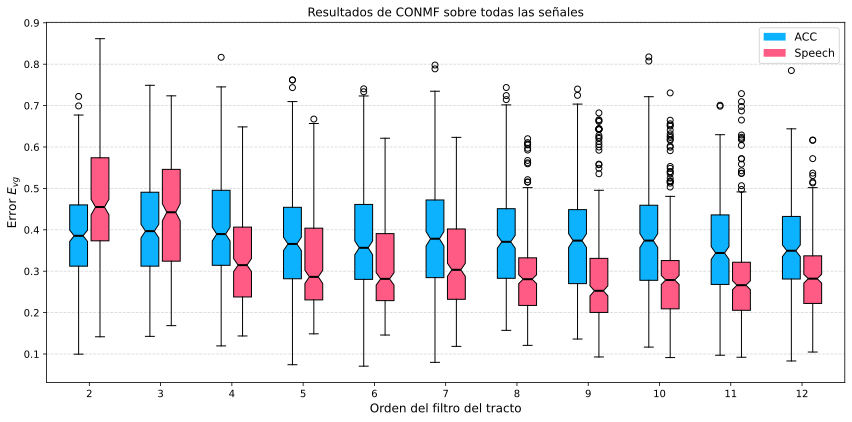

In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
%config InlineBackend.figure_format = 'svg'

# ==========================================================
# Configuración
# ==========================================================
carpeta_csv = Path("Resultados boxplots")   # ajustá la ruta según donde estén los archivos
ordenes = list(range(2, 13))                # 2, 3, ..., 12

color_a = "#0DB2FF"
color_i = "#FF5B84"

pair_gap = 0.15   # separación entre la caja de A y la de I dentro de cada orden
width_caja = 0.25

# ==========================================================
# Cargo los datos de cada archivo
# ==========================================================
datos_acc = []
datos_speech = []
ordenes_disponibles = []

for n in ordenes:
    ruta = carpeta_csv / f"Todas_{n}.csv"

    if not ruta.exists():
        print(f"Aviso: no se encontró {ruta}, se omite orden {n}")
        continue

    df = pd.read_csv(ruta)

    valores_acc = df["CONMF_acc_a"].dropna().values
    valores_speech = df["CONMF_speech_a"].dropna().values

    datos_acc.append(valores_acc)
    datos_speech.append(valores_speech)
    ordenes_disponibles.append(n)

# ==========================================================
# Armo las posiciones: una caja A y una I por cada orden
# ==========================================================
posiciones_a = [n - pair_gap for n in ordenes_disponibles]
posiciones_i = [n + pair_gap for n in ordenes_disponibles]

fig, ax = plt.subplots(figsize=(12, 6))

bp_a = ax.boxplot(
    datos_acc,
    positions=posiciones_a,
    widths=width_caja,
    showmeans=False,
    showfliers=True,
    patch_artist=True,
    notch = True,
)

bp_i = ax.boxplot(
    datos_speech,
    positions=posiciones_i,
    widths=width_caja,
    showmeans=False,
    showfliers=True,
    patch_artist=True,
    notch = True,
)

for box in bp_a['boxes']:
    box.set_facecolor(color_a)
for box in bp_i['boxes']:
    box.set_facecolor(color_i)

for median in bp_a['medians'] + bp_i['medians']:
    median.set_color('black')
    median.set_linewidth(2)

# ==========================================================
# Ejes y leyenda
# ==========================================================
ax.set_xticks(ordenes_disponibles)
ax.set_xticklabels(ordenes_disponibles)
ax.set_xlim(min(ordenes_disponibles) - 0.6, max(ordenes_disponibles) + 0.6)

ax.set_xlabel("Orden del filtro del tracto", fontsize=12)
ax.set_ylabel(r"Error $E_{vg}$", fontsize=12)

legend_elements = [
    Patch(facecolor=color_a, label='ACC'),
    Patch(facecolor=color_i, label='Speech'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=11)

ax.grid(True, axis='y', linestyle='--', alpha=0.5)
ax.set_title("Resultados de CONMF sobre todas las señales")
plt.tight_layout()
plt.show()

# Interfaz con opcion de filtrado y diferencias medidas

In [ ]:
# Interfaz
from ipyfilechooser import FileChooser
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
import numpy as np
import scipy.signal as sig
import NNMF_GIF2 as CONMF
import NNMF_GIF as NMF
import Funciones as Funciones
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial
%config InlineBackend.figure_format = 'svg'
from MetricasRendimiento import MetricasRendimiento
import ray
from matplotlib.backends.backend_pdf import PdfPages
import textwrap
import pandas as pd
import re
from datetime import datetime
import traceback

#========================================================================================================================================
# Variables generales
#========================================================================================================================================
cmap = Funciones.parula_map
color_ACC = 'blue'
color_EGG = 'orange'
color_dEGG = 'g'
color_OVV = 'magenta'
color_speech = 'black'
legend_loc = 'upper right'
color1 = 'red'
color2 = 'blue'
color3 = 'k'
color_notch = 'green'
color_lpc  = 'orange'
color_flujo = 'k'
line_width = 1.5

@ray.remote
def procesar_archivo(nombre, carpeta_base, vocal, parametros):
    ruta_archivo = Path(carpeta_base) / nombre
    df = pd.read_csv(ruta_archivo, sep=',')

    fs_r = 8000
    tiempos = df['t_ms'].values
    t0_analisis = 5 #ms 
    tf_analisis = 45#ms
    mascara_tiempos = (tiempos >= t0_analisis) & (tiempos <= tf_analisis)
    tiempos_analisis = tiempos[mascara_tiempos]
    flujo_OVV   = df['flujo_OVV'].values[mascara_tiempos]

    parametros["CONMF"]["mascara_tiempos"] = mascara_tiempos
    parametros["NMF_speech"]["mascara_tiempos"] = mascara_tiempos
    parametros["NMF_acc"]["mascara_tiempos"] = mascara_tiempos
    # ==================================================================
    señal_MBK  = df['MBK'].values
    señal_MBK  = señal_MBK - np.mean(señal_MBK)
    señal_ACC  = -df['ACC'].values
    señal_ACC  = señal_ACC - np.mean(señal_ACC)
    señal_EGG = df['MBK'].values
    señal_EGG = Funciones.Detrend(tiempos, señal_EGG)
    señal_dEGG = np.gradient(señal_EGG)

    dflujo_OVV = np.gradient(flujo_OVV)

    # ==================================================================
    # Configuración del filtrado post-procesamiento (depende de la vocal)
    filtro_cfg = parametros["filtro"]
    aplicar_filtro = filtro_cfg["aplicar"]

    if vocal == 'A':
        orden_filtro_pb = filtro_cfg["A"]["orden"]
        fc_filtro_pb    = filtro_cfg["A"]["fc"]
    else:
        orden_filtro_pb = filtro_cfg["I"]["orden"]
        fc_filtro_pb    = filtro_cfg["I"]["fc"]

    def filtrar_flujo(flujo):
        """Aplica (o no) el filtro pasabajos configurado y recalcula la derivada."""
        if aplicar_filtro:
            flujo_filtrado, _, _ = Funciones.LP_Filter(flujo, fs=fs_r, fc=fc_filtro_pb, order=orden_filtro_pb)
        else:
            flujo_filtrado = flujo
        dflujo_filtrado = np.gradient(flujo_filtrado)
        return flujo_filtrado, dflujo_filtrado

    # ==================================================================
    # CONMF
    resultado_CONMF = CONMF.NNMF_GIF(speech=señal_MBK, acelerometro=señal_ACC, dEGG=señal_dEGG, tiempos=tiempos, fs=fs_r, **parametros["CONMF"])
    resultado_CONMF.flujo1_speech, resultado_CONMF.dflujo1_speech = filtrar_flujo(resultado_CONMF.flujo1_speech)
    resultado_CONMF.flujo1_acc, resultado_CONMF.dflujo1_acc       = filtrar_flujo(resultado_CONMF.flujo1_acc)

    # ==================================================================
    # NMF SPEECH
    resultado_NMF_speech = NMF.NNMF_GIF(señal=señal_MBK, dEGG=señal_dEGG, tiempos=tiempos, fs=fs_r, **parametros["NMF_speech"])
    resultado_NMF_speech.flujo1, resultado_NMF_speech.dflujo1 = filtrar_flujo(resultado_NMF_speech.flujo1)

    # ==================================================================
    # NMF ACC
    resultado_NMF_acc = NMF.NNMF_GIF(señal=señal_ACC, dEGG=señal_dEGG, tiempos=tiempos, fs=fs_r, **parametros["NMF_acc"])
    resultado_NMF_acc.flujo1, resultado_NMF_acc.dflujo1 = filtrar_flujo(resultado_NMF_acc.flujo1)

    # ==================================================================
    # METRICAS
    # tipo_error: 'flujo'  -> error calculado sobre el flujo glótico
    #             'dflujo' -> error calculado sobre la función glótica (derivada del flujo)
    tipo_error = parametros["tipo_error"]

    if tipo_error == 'flujo':
        referencia          = flujo_OVV
        señal_NMF_speech     = resultado_NMF_speech.flujo1
        señal_NMF_acc        = resultado_NMF_acc.flujo1
        señal_CONMF_speech   = resultado_CONMF.flujo1_speech
        señal_CONMF_acc      = resultado_CONMF.flujo1_acc
    else:
        referencia          = dflujo_OVV
        señal_NMF_speech     = resultado_NMF_speech.dflujo1
        señal_NMF_acc        = resultado_NMF_acc.dflujo1
        señal_CONMF_speech   = resultado_CONMF.dflujo1_speech
        señal_CONMF_acc      = resultado_CONMF.dflujo1_acc

    MR_NMF_speech_1   = MetricasRendimiento(referencia, señal_NMF_speech, tiempos_analisis)
    MR_NMF_acc_1      = MetricasRendimiento(referencia, señal_NMF_acc, tiempos_analisis)
    MR_CONMF_speech_1 = MetricasRendimiento(referencia, señal_CONMF_speech, tiempos_analisis)
    MR_CONMF_acc_1    = MetricasRendimiento(referencia, señal_CONMF_acc, tiempos_analisis)

    return {
        "NMF_speech": MR_NMF_speech_1.Error,
        "NMF_acc": MR_NMF_acc_1.Error,
        "CONMF_speech": MR_CONMF_speech_1.Error,
        "CONMF_acc": MR_CONMF_acc_1.Error,
    }

#========================================================================================================================================
def _limpiar(lista):
    """Convierte a array de numpy y descarta NaN."""
    arr = np.array(lista, dtype=float)
    return arr[~np.isnan(arr)]

#========================================================================================================================================
def ejecutar(b):

    global resultados_errores

    # ==============================================================
    # Vocal asignada a cada archivo (elegida por el usuario, sin asumir un orden fijo)

    vocal1 = vocal_archivo1.value
    vocal2 = vocal_archivo2.value

    if vocal1 == vocal2:
        with tab_boxplots:
            clear_output(wait=True)
            print("Error: los dos archivos tienen la misma vocal asignada (deben ser 'A' e 'I', una para cada uno).")
        return

    # Estructura de resultados indexada por vocal, no por posición del archivo,
    # de forma que sea indistinto si /a/ se cargó como archivo 1 o como archivo 2.
    resultados_errores = {
        'A': {'NMF_speech': [], 'NMF_acc': [], 'CONMF_speech': [], 'CONMF_acc': []},
        'I': {'NMF_speech': [], 'NMF_acc': [], 'CONMF_speech': [], 'CONMF_acc': []},
    }

    # ==============================================================
    # Arranco el Ray

    ray.shutdown()
    ray.init(ignore_reinit_error=True)

    # ==============================================================

    lista_señales1 = Path(fc1.selected)
    lista_señales2 = Path(fc2.selected)
    carpeta_base1 = lista_señales1.parent
    carpeta_base2 = lista_señales2.parent

    with open(lista_señales1, "r", encoding="utf-8") as f:
        nombres_archivos1 = [linea.strip() for linea in f if linea.strip()]

    with open(lista_señales2, "r", encoding="utf-8") as f:
        nombres_archivos2 = [linea.strip() for linea in f if linea.strip()]

    total_archivos = len(nombres_archivos1) + len(nombres_archivos2)
    barra_progreso.max = total_archivos
    barra_progreso.value = 0

    label_progreso.value = f'0/{total_archivos}'

    # ==============================================================
    parametros = {
        "CONMF": {
            "norma": conmf_norma.value,
            "pre_iteraciones": conmf_pre_iteraciones.value,
            "iteraciones": conmf_iteraciones.value,
            "T": conmf_T.value,
            "delta": conmf_delta.value,
            "p_filtro_speech": conmf_p_filtro_speech.value,
            "alfa_speech": conmf_alfa_speech.value,
            "p_filtro_acc": conmf_p_filtro_acc.value,
            "alfa_acc": conmf_alfa_acc.value,
            "beta_speech": conmf_beta_speech.value,
            "beta_acc": conmf_beta_acc.value,
            "pre_enfasis_speech": conmf_pre_enfasis_speech.value,
            "pre_enfasis_acc": conmf_pre_enfasis_acc.value,
            "duracion": conmf_duracion_ventana.value,
            "guardar_proceso": conmf_guardar_proceso.value,
            "normalizar_espectrogramas": conmf_normalizar_espectrogramas.value,
            "ventana": conmf_ventana.value
        },
        "NMF_speech": {
            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "T": nmf_T.value,
            "delta": nmf_delta.value,
            "p_filtro": nmf_p_filtro_speech.value,
            "alfa": nmf_alfa_speech.value,
            "beta": nmf_beta_speech.value,
            "pre_enfasis": nmf_pre_enfasis_speech.value,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        },
        "NMF_acc": {
            "norma": nmf_norma.value,
            "pre_iteraciones": nmf_pre_iteraciones.value,
            "iteraciones": nmf_iteraciones.value,
            "T": nmf_T.value,
            "delta": nmf_delta.value,
            "p_filtro": nmf_p_filtro_acc.value,
            "alfa": nmf_alfa_acc.value,
            "beta": nmf_beta_acc.value,
            "pre_enfasis": nmf_pre_enfasis_acc.value,
            "duracion": nmf_duracion_ventana.value,
            "guardar_proceso": nmf_guardar_proceso.value,
            "ventana": nmf_ventana.value
        },
        # --------------------------------------------------------------
        # Filtrado post-procesamiento aplicado a flujo/dflujo, distinto por vocal
        "filtro": {
            "aplicar": filtro_aplicar.value,
            "A": {
                "orden": filtro_orden_A.value,
                "fc": filtro_fc_A.value,
            },
            "I": {
                "orden": filtro_orden_I.value,
                "fc": filtro_fc_I.value,
            },
        },
        # --------------------------------------------------------------
        # Sobre qué señal se calcula el error: 'flujo' o 'dflujo'
        "tipo_error": tipo_error_dropdown.value,
    }

    # ==============================================================
    # Ejecuto las tareas.
    # Cada tarea de futures1 usa vocal1 y cada tarea de futures2 usa vocal2:
    # da igual qué vocal se haya elegido para cada archivo, el resultado
    # se acumula correctamente en resultados_errores[vocal1] / [vocal2].
    futures1 = [procesar_archivo.remote(nombre, str(carpeta_base1), vocal1, parametros) for nombre in nombres_archivos1]
    futures2 = [procesar_archivo.remote(nombre, str(carpeta_base2), vocal2, parametros) for nombre in nombres_archivos2]

    # ==============================================================
    # Obtengo los resultados
    restantes1 = futures1
    restantes2 = futures2
    procesados = 0

    while restantes1:
        terminados, restantes1 = ray.wait(restantes1)
        resultado = ray.get(terminados[0])
        resultados_errores[vocal1]['CONMF_speech'].append(resultado["CONMF_speech"])
        resultados_errores[vocal1]['CONMF_acc'].append(resultado["CONMF_acc"])
        resultados_errores[vocal1]['NMF_speech'].append(resultado["NMF_speech"])
        resultados_errores[vocal1]['NMF_acc'].append(resultado["NMF_acc"])

        procesados += 1
        barra_progreso.value = procesados
        label_progreso.value = (f'{procesados}/{total_archivos}')

    while restantes2:
        terminados, restantes2 = ray.wait(restantes2)
        resultado = ray.get(terminados[0])

        resultados_errores[vocal2]['CONMF_speech'].append(resultado["CONMF_speech"])
        resultados_errores[vocal2]['CONMF_acc'].append(resultado["CONMF_acc"])
        resultados_errores[vocal2]['NMF_speech'].append(resultado["NMF_speech"])
        resultados_errores[vocal2]['NMF_acc'].append(resultado["NMF_acc"])

        procesados += 1
        barra_progreso.value = procesados
        label_progreso.value = (f'{procesados}/{total_archivos}')

    with tab_boxplots:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(12, 6))
        color_NMF = "#0505058F"
        color_CONMF = "#79FF74"

        modo = modo_agrupamiento.value  # 'separado' o 'conjunto'

        if modo == 'separado':
            # El orden de graficado (/a/ primero, /i/ segundo) queda fijo,
            # independientemente de qué archivo se haya asignado a cada vocal.
            datos = [
                # Vocal A para el speech
                _limpiar(resultados_errores['A']['NMF_speech']),
                _limpiar(resultados_errores['A']['CONMF_speech']),

                # Vocal I para el speech
                _limpiar(resultados_errores['I']['NMF_speech']),
                _limpiar(resultados_errores['I']['CONMF_speech']),

                # Vocal A para el acc
                _limpiar(resultados_errores['A']['NMF_acc']),
                _limpiar(resultados_errores['A']['CONMF_acc']),

                # Vocal I para el acc
                _limpiar(resultados_errores['I']['NMF_acc']),
                _limpiar(resultados_errores['I']['CONMF_acc']),
            ]

            labels = ['/a/', '/i/', '/a/', '/i/']
            algos = ['NMF', 'CONMF', 'NMF', 'CONMF', 'NMF', 'CONMF', 'NMF', 'CONMF']
            columnas_csv = [
                'NMF_speech_a', 'CONMF_speech_a',
                'NMF_speech_i', 'CONMF_speech_i',
                'NMF_acc_a', 'CONMF_acc_a',
                'NMF_acc_i', 'CONMF_acc_i',
            ]

            pair_gap = 0.2
            group_gap = 1.0
            block_gap = 1.6

            pair_centers = [
                1.0,
                1.0 + group_gap,
                1.0 + group_gap + block_gap,
                1.0 + 2 * group_gap + block_gap
            ]

            positions = []
            for c in pair_centers:
                positions += [c - pair_gap, c + pair_gap]

        else:
            # Modo conjunto: se combinan los resultados de ambas vocales
            # (/a/ e /i/) en una única distribución por algoritmo y tipo de señal.
            datos = [
                _limpiar(resultados_errores['A']['NMF_speech'] + resultados_errores['I']['NMF_speech']),
                _limpiar(resultados_errores['A']['CONMF_speech'] + resultados_errores['I']['CONMF_speech']),
                _limpiar(resultados_errores['A']['NMF_acc'] + resultados_errores['I']['NMF_acc']),
                _limpiar(resultados_errores['A']['CONMF_acc'] + resultados_errores['I']['CONMF_acc']),
            ]

            labels = ['Speech', 'Speech', 'ACC', 'ACC']
            algos = ['NMF', 'CONMF', 'NMF', 'CONMF']
            columnas_csv = ['NMF_speech', 'CONMF_speech', 'NMF_acc', 'CONMF_acc']

            pair_gap = 0.2
            block_gap = 1.6

            pair_centers = [1.0, 1.0 + block_gap]

            positions = []
            for c in pair_centers:
                positions += [c - pair_gap, c + pair_gap]

        bp = ax.boxplot(
            datos,
            positions=positions,
            widths=0.3,
            showmeans=False,
            showfliers=True,
            patch_artist=True,
            notch=True,
        )

        for box, algo in zip(bp['boxes'], algos):
            box.set_facecolor(color_NMF if algo == 'NMF' else color_CONMF)

        for median in bp['medians']:
            median.set_color('black')
            median.set_linewidth(2)

        ax.set_xlim(positions[0] - 0.5, positions[-1] + 0.5)

        if modo == 'separado':
            ax.set_xticks(pair_centers)
            ax.set_xticklabels(['/a/', '/i/', '/a/', '/i/'], fontsize=11)

            divider_x = (pair_centers[1] + pair_centers[2]) / 2
            ax.axvline(divider_x, color='gray', linestyle=':', linewidth=1)

            trans = ax.get_xaxis_transform()
            voz_center = (pair_centers[0] + pair_centers[1]) / 2
            acc_center = (pair_centers[2] + pair_centers[3]) / 2
            ax.text(voz_center, -0.12, 'Speech', transform=trans, ha='center', va='top', fontsize=13, fontweight='bold')
            ax.text(acc_center, -0.12, 'ACC', transform=trans, ha='center', va='top', fontsize=13, fontweight='bold')
        else:
            # En modo conjunto cada bloque ya es un único par (NMF/CONMF),
            # así que la etiqueta de bloque va directamente como xtick.
            ax.set_xticks(pair_centers)
            ax.set_xticklabels(['Speech', 'ACC'], fontsize=13, fontweight='bold')

            divider_x = (pair_centers[0] + pair_centers[1]) / 2
            ax.axvline(divider_x, color='gray', linestyle=':', linewidth=1)

        from matplotlib.patches import Patch
        legend_elements = [
            Patch(facecolor=color_NMF, label='NMF'),
            Patch(facecolor=color_CONMF, label='CONMF'),
        ]

        ax.legend(
            handles=legend_elements,
            loc='lower center',
            bbox_to_anchor=(0.5, 1.02),
            ncol=2,
            frameon=False,
            fontsize=14
        )

        etiqueta_y = r"Error $E_{vg}$ (flujo)" if tipo_error_dropdown.value == 'flujo' else r"Error $E_{vg}$ (función glótica)"
        ax.set_ylabel(etiqueta_y, fontsize=12)

        titulo_modo = "todas las señales combinadas" if modo == 'conjunto' else "separado por vocal"
        ax.set_title(f"Resultados ({titulo_modo})", fontsize=13)

        plt.tight_layout()
        plt.show()

        # ==========================================================
        # Genero el pdf y el csv

        carpeta_resultados = Path("Resultados boxplots")
        carpeta_resultados.mkdir(parents=True, exist_ok=True)

        fecha_hora = datetime.now().astimezone().strftime("%d-%m_%H-%M-%S")

        # Nombre elegido por el usuario (si lo hay); si no, se usa fecha/hora como antes.
        nombre_personalizado = nombre_pdf_text.value.strip()
        if nombre_personalizado:
            # Quito extensiones que el usuario pueda haber tipeado y saneo caracteres inválidos para nombre de archivo
            nombre_personalizado = re.sub(r'\.(pdf|csv)$', '', nombre_personalizado, flags=re.IGNORECASE)
            nombre_base = re.sub(r'[\\/*?:"<>|]', "_", nombre_personalizado)
        else:
            nombre_base = f"Boxplot_{fecha_hora}"

        ruta_pdf = carpeta_resultados / f"{nombre_base}.pdf"
        ruta_csv = carpeta_resultados / f"{nombre_base}.csv"

        with PdfPages(ruta_pdf) as pdf:

            # ------------------------------------------------------
            # Página 1 - La figura

            pdf.savefig(fig, bbox_inches='tight')

            # ------------------------------------------------------
            # Página 2 - La información

            fig_texto = plt.figure(figsize=(8.27, 11.69))  # A4

            texto = ""

            texto += "Archivo:\n"
            texto += "============================\n\n"
            texto += f"Archivo 1 (vocal /{vocal1.lower()}/): {lista_señales1.name.removesuffix('.txt')}\n\n"
            texto += f"Archivo 2 (vocal /{vocal2.lower()}/): {lista_señales2.name.removesuffix('.txt')}\n\n"
            texto += "\n\n"
            texto += "Cantidad de ventanas analizadas:\n"
            texto += "============================\n\n"
            texto += f"{total_archivos}\n\n"
            texto += "\n\n"
            texto += "Métrica de error:\n"
            texto += "============================\n\n"
            texto += f"Calculada sobre: {'Flujo glótico' if tipo_error_dropdown.value == 'flujo' else 'Función glótica (dflujo)'}\n\n"
            texto += "\n\n"
            texto += "Agrupamiento del boxplot:\n"
            texto += "============================\n\n"
            texto += f"{'Conjunto (todas las señales combinadas, sin separar por vocal)' if modo == 'conjunto' else 'Separado por vocal (/a/ vs /i/)'}\n\n"
            texto += "\n\n"
            texto += "Filtrado post-procesamiento:\n"
            texto += "============================\n\n"
            if filtro_aplicar.value:
                texto += f"Aplicado. Vocal /a/ -> orden={filtro_orden_A.value}, fc={filtro_fc_A.value} Hz\n"
                texto += f"          Vocal /i/ -> orden={filtro_orden_I.value}, fc={filtro_fc_I.value} Hz\n\n"
            else:
                texto += "No aplicado\n\n"
            texto += "\n\n"
            texto += "Parámetros\n"
            texto += "============================\n\n"

            for grupo, diccionario in parametros.items():
                if grupo in ("filtro", "tipo_error"):
                    continue

                texto += f"[{grupo}]\n\n"

                for clave, valor in diccionario.items():
                    texto += f"{clave}: {valor}\n"

                texto += "\n"

            texto = "\n".join(
                textwrap.fill(linea, width=95)
                for linea in texto.split("\n")
            )

            fig_texto.text(
                0.03,
                0.97,
                texto,
                va='top',
                ha='left',
                fontsize=10,
                family='monospace'
            )

            plt.axis('off')

            pdf.savefig(fig_texto, bbox_inches='tight')

            plt.close(fig_texto)

        # ==========================================================
        # Genero el csv con los datos de los boxplots
        # (columnas_csv ya quedó definida más arriba, según el modo elegido)

        df_resultados = pd.DataFrame({
            columna: pd.Series(valores)
            for columna, valores in zip(columnas_csv, datos)
        })

        df_resultados.to_csv(ruta_csv, index=False)

#========================================================================================================================================
# Títulos de las secciones
#========================================================================================================================================
titulo_archivo = widgets.HTML(
    value="<b>Archivo</b>"
)
titulo_filtrado_metrica = widgets.HTML(
    value="<b>Filtrado y Métricas</b>"
)
titulo_CONMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#8080ff; color:white; padding:10px;'>
        CO-NMF
    </div>
    """
)
titulo_NMF = widgets.HTML(
    value="""
    <div style='width:100%; font-size:36px; font-weight:bold; background-color:#ff7878; color:white; padding:10px;'>
        NMF
    </div>
    """
)
subtitulo_espectrograma = widgets.HTML(
    value="<b>Espectrograma</b>"
)
subtitulo_speech = widgets.HTML(
    value="<b>Speech</b>"
)
subtitulo_acc = widgets.HTML(
    value="<b>ACC</b>"
)
subtitulo_nmf = widgets.HTML(
    value="<b>NNMF</b>"
)
subtitulo_gif = widgets.HTML(
    value="<b>GIF</b>"
)
subtitulo_filtro_vocal_a = widgets.HTML(
    value="Vocal /a/"
)
subtitulo_filtro_vocal_i = widgets.HTML(
    value="Vocal /i/"
)
linea_divisoria = widgets.HTML(
    value="<hr style='border:1px solid #ccc; margin:10px 0;'>"
)
#========================================================================================================================================
# Archivo y botón
#========================================================================================================================================

fc1 = FileChooser('Señales VEC')
fc1.layout = widgets.Layout(width='auto')

fc2 = FileChooser('Señales VEC')
fc2.layout = widgets.Layout(width='auto')

# Selector de vocal correspondiente a cada archivo: permite elegir libremente
# cuál de los dos archivos es /a/ y cuál es /i/, sin asumir un orden fijo.
vocal_archivo1 = widgets.Dropdown(
    options=['A', 'I'],
    value='A',
    description='Vocal:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='120px')
)
vocal_archivo2 = widgets.Dropdown(
    options=['A', 'I'],
    value='I',
    description='Vocal:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='120px')
)

boton_ejecutar = widgets.Button(
    description="Ejecutar",
    button_style='success'
)

barra_progreso = widgets.IntProgress(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Progreso:',
    bar_style='info',
    orientation='horizontal',
    layout=widgets.Layout(width='300px')
)

label_progreso = widgets.Label(value='0/0')

grid_señal_1 = widgets.GridBox(
    children=[fc1, vocal_archivo1],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_señal_2 = widgets.GridBox(
    children=[fc2, vocal_archivo2],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

grid_archivo_boton = widgets.GridBox(
    children=[boton_ejecutar, barra_progreso, label_progreso],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_gap='10px 20px',
        width='90%'
    )
)

#========================================================================================================================================
# Filtrado post-procesamiento (flujo / dflujo, distinto por vocal) y selección de métrica / nombre de PDF
#========================================================================================================================================
filtro_aplicar = widgets.Checkbox(
    value=True,
    description='Aplicar filtrado pasabajos a la solución (flujo/dflujo)'
)

filtro_orden_A = widgets.BoundedIntText(
    value=8,
    min=1,
    max=20,
    step=1,
    description='Orden:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_fc_A = widgets.BoundedFloatText(
    value=900,
    min=50,
    max=4000,
    step=10,
    description='fc (Hz):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_orden_I = widgets.BoundedIntText(
    value=10,
    min=1,
    max=20,
    step=1,
    description='Orden:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
filtro_fc_I = widgets.BoundedFloatText(
    value=500,
    min=50,
    max=4000,
    step=10,
    description='fc (Hz):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)

grid_filtro_A = widgets.GridBox(
    children=[subtitulo_filtro_vocal_a, filtro_orden_A, filtro_fc_A],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
grid_filtro_I = widgets.GridBox(
    children=[subtitulo_filtro_vocal_i, filtro_orden_I, filtro_fc_I],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)

tipo_error_dropdown = widgets.Dropdown(
    options=[('Función glótica (dflujo)', 'dflujo'), ('Flujo glótico (flujo)', 'flujo')],
    value='dflujo',
    description='Error calculado sobre:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='320px')
)

nombre_pdf_text = widgets.Text(
    value='',
    placeholder='Vacío = nombre automático por fecha/hora',
    description='Nombre del PDF:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='400px')
)

grid_metrica_pdf = widgets.GridBox(
    children=[tipo_error_dropdown, nombre_pdf_text],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 20px',
        width='90%'
    )
)

# Modo de agrupamiento del boxplot: separar por vocal (/a/ vs /i/) o combinar
# ambas vocales en una única distribución por algoritmo (Speech/ACC).
# Nota: los 2 archivos y la vocal asignada a cada uno se siguen usando igual
# que antes (entre otras cosas, para saber qué filtro aplicar a cada señal);
# esta opción sólo afecta cómo se agrupan los resultados en el boxplot final.
modo_agrupamiento = widgets.ToggleButtons(
    options=[('Separado por vocal (/a/ vs /i/)', 'separado'), ('Conjunto (todas las señales juntas)', 'conjunto')],
    value='separado',
    description='Agrupamiento del boxplot:',
    style={'description_width': 'initial'},
)

#========================================================================================================================================
# Elementos de CO-NMF
#========================================================================================================================================
conmf_norma = widgets.Dropdown(
    options=['frobenius', 'itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
conmf_ventana = widgets.Dropdown(
    options=['Rectangular', 'Hanning', 'Blackman', 'Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
conmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px'),
)
conmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
conmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)

conmf_delta = widgets.BoundedFloatText(
    value=10e-4,
    min=10e-6,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)

conmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
conmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
conmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
conmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
conmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
conmf_normalizar_espectrogramas = widgets.Checkbox(
    value=True,
    description='Normalizar espectrogramas'
)
conmf_grid_speech = widgets.GridBox(
    children=[conmf_pre_enfasis_speech, conmf_beta_speech, conmf_p_filtro_speech, conmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
conmf_grid_acc = widgets.GridBox(
    children=[conmf_pre_enfasis_acc, conmf_beta_acc, conmf_p_filtro_acc, conmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
conmf_grid_espectrograma = widgets.GridBox(
    children=[conmf_ventana, conmf_duracion_ventana, conmf_desplazamiento, conmf_normalizar_espectrogramas],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
conmf_grid_nmf = widgets.GridBox(
    children=[conmf_norma, conmf_iteraciones, conmf_T, conmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)

#========================================================================================================================================
# Elementos de NMF
#========================================================================================================================================
nmf_norma = widgets.Dropdown(
    options=['frobenius', 'itakura-saito'],
    value='frobenius',
    description='Norma:',
    layout=widgets.Layout(width='300px')
)
nmf_ventana = widgets.Dropdown(
    options=['Rectangular', 'Hanning', 'Blackman', 'Hamming'],
    value='Rectangular',
    description='Ventana:',
    layout=widgets.Layout(width='200px')
)
nmf_duracion_ventana = widgets.BoundedFloatText(
    value=5.5,
    min=1.0,
    max=20.0,
    step=0.5,
    description='Duración ventana (ms):',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_desplazamiento = widgets.BoundedIntText(
    value=1,
    min=1,
    max=10,
    step=1,
    description='hop:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px'),
)
nmf_pre_iteraciones = widgets.BoundedIntText(
    value=0,
    min=0,
    max=100,
    step=1,
    description='Pre-iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_iteraciones = widgets.BoundedIntText(
    value=250,
    min=1,
    max=50000,
    step=1,
    description='Iteraciones:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='150px')
)
nmf_delta = widgets.BoundedFloatText(
    value=10e-4,
    min=10e-6,
    max=1.0,
    step=1e-5,
    description='δ:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_T = widgets.BoundedIntText(
    value=10,
    min=1,
    max=100,
    step=1,
    description='T:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)

nmf_p_filtro_speech = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_speech = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_p_filtro_acc = widgets.BoundedIntText(
    value=12,
    min=2,
    max=20,
    step=1,
    description='Orden del filtro del tracto:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='200px')
)
nmf_alfa_acc = widgets.BoundedFloatText(
    value=0.96,
    min=0.0,
    max=1.0,
    step=0.01,
    description='α:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='75px')
)
nmf_beta_speech = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_beta_acc = widgets.BoundedFloatText(
    value=0.55,
    min=0.1,
    max=2.0,
    step=0.05,
    description='β:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='100px')
)
nmf_pre_enfasis_speech = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_pre_enfasis_acc = widgets.Checkbox(
    value=True,
    description='Pre-énfasis'
)
nmf_guardar_proceso = widgets.Checkbox(
    value=True,
    description='Guardar proceso'
)
nmf_grid_speech = widgets.GridBox(
    children=[nmf_pre_enfasis_speech, nmf_beta_speech, nmf_p_filtro_speech, nmf_alfa_speech],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_acc = widgets.GridBox(
    children=[nmf_pre_enfasis_acc, nmf_beta_acc, nmf_p_filtro_acc, nmf_alfa_acc],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 5px',
        width='60%'
    )
)
nmf_grid_espectrograma = widgets.GridBox(
    children=[nmf_ventana, nmf_duracion_ventana, nmf_desplazamiento],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)
nmf_grid_nmf = widgets.GridBox(
    children=[nmf_norma, nmf_iteraciones, nmf_T, nmf_delta],
    layout=widgets.Layout(
        display='grid',
        grid_auto_flow='column',
        grid_auto_columns='auto',
        grid_gap='0px 10px',
        width='60%'
    )
)

#========================================================================================================================================
# Ensamble de la estructura de la intefaz
#========================================================================================================================================
estructura_interfaz = widgets.VBox([
    titulo_archivo,
    grid_señal_1,
    linea_divisoria,
    grid_señal_2,
    linea_divisoria,
    grid_archivo_boton,
    linea_divisoria,
    titulo_filtrado_metrica,
    filtro_aplicar,
    grid_filtro_A,
    grid_filtro_I,
    linea_divisoria,
    grid_metrica_pdf,
    linea_divisoria,
    modo_agrupamiento,
    linea_divisoria,
    titulo_CONMF,
    linea_divisoria,
    subtitulo_speech,
    conmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    conmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    conmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    conmf_grid_nmf,
    linea_divisoria,
    titulo_NMF,
    linea_divisoria,
    subtitulo_speech,
    nmf_grid_speech,
    linea_divisoria,
    subtitulo_acc,
    nmf_grid_acc,
    linea_divisoria,
    subtitulo_espectrograma,
    nmf_grid_espectrograma,
    linea_divisoria,
    subtitulo_nmf,
    nmf_grid_nmf,
    linea_divisoria
])
#========================================================================================================================================
# Configuración de las pestañas
#========================================================================================================================================
tab_boxplots = widgets.Output()


tab = widgets.Tab(children=[
    estructura_interfaz,
    tab_boxplots
])
tab.set_title(0, 'Configuración')
tab.set_title(1, 'Boxplots')

boton_ejecutar.on_click(ejecutar)
display(tab)

KeyError: 'ok'

KeyError: 'ok'